<a href="https://colab.research.google.com/github/govrahul/aipi510_project3/blob/Daniel-data-cleaning/water_potability_cleaning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [19]:
DROP_TURBIDITY = False        # set False if you decide to keep turbidity as an input
DROP_SOLIDS = True
LAB_ONLY_COLS = ["Organic_carbon", "Trihalomethanes"]
TARGET = "Potability"
OUTPUT_CSV = "water_potability_clean.csv"
OUTPUT_META = "feature_metadata.json"

Dissolved solids are mostly salts and minerals, and those are what let water conduct electricity. More dissolved stuff means higher conductivity. That’s why a cheap TDS pen doesn’t measure solids directly: it measures conductivity and multiplies by about 0.6. So in real water, if you know one, you basically know the other.

In [20]:
!pip install -q kagglehub

import glob, json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

path = kagglehub.dataset_download("uom190346a/water-quality-and-potability")
print("Path to dataset files:", path)
print(os.listdir(path))

Using Colab cache for faster access to the 'water-quality-and-potability' dataset.
Path to dataset files: /kaggle/input/water-quality-and-potability
['water_potability.csv']


In [21]:
csv_files = glob.glob(os.path.join(path, "*.csv"))
assert len(csv_files) == 1, f"Expected one CSV, found: {csv_files}"
raw = pd.read_csv(csv_files[0])

print("Shape:", raw.shape)
display(raw.head())
raw.info()

Shape: (3276, 10)


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3276 entries, 0 to 3275
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ph               2785 non-null   float64
 1   Hardness         3276 non-null   float64
 2   Solids           3276 non-null   float64
 3   Chloramines      3276 non-null   float64
 4   Sulfate          2495 non-null   float64
 5   Conductivity     3276 non-null   float64
 6   Organic_carbon   3276 non-null   float64
 7   Trihalomethanes  3114 non-null   float64
 8   Turbidity        3276 non-null   float64
 9   Potability       3276 non-null   int64  
dtypes: float64(9), int64(1)
memory usage: 256.1 KB


Potability: 1/0, potable/not
Missing pH, Sulfate, Trihalomethanes

In [22]:
display(raw.describe().T)

,count,mean,std,min,25%,50%,75%,max
ph,2785.0,7.080795,1.594320,0.000000,6.093092,7.036752,8.062066,14.000000
Hardness,3276.0,196.369496,32.879761,47.432000,176.850538,196.967627,216.667456,323.124000
Solids,3276.0,22014.092526,8768.570828,320.942611,15666.690297,20927.833607,27332.762127,61227.196008
Chloramines,3276.0,7.122277,1.583085,0.352000,6.127421,7.130299,8.114887,13.127000
Sulfate,2495.0,333.775777,41.416840,129.000000,307.699498,333.073546,359.950170,481.030642
Conductivity,3276.0,426.205111,80.824064,181.483754,365.734414,421.884968,481.792304,753.342620
Organic_carbon,3276.0,14.284970,3.308162,2.200000,12.065801,14.218338,16.557652,28.300000
Trihalomethanes,3114.0,66.396293,16.175008,0.738000,55.844536,66.622485,77.337473,124.000000
Turbidity,3276.0,3.966786,0.780382,1.450000,3.439711,3.955028,4.500320,6.739000
Potability,3276.0,0.390110,0.487849,0.000000,0.000000,0.000000,1.000000,1.000000


### Comparison with EPA drinking water standards

| Feature | EPA limit | This dataset | Verdict |
|---|---|---|---|
| pH | 6.5–8.5 (secondary) | 25th pct 6.09, min 0, max 14 | 25%+ of rows below 6.5; extremes impossible for water |
| Solids (TDS) | 500 mg/L (secondary) | min 321, 25th pct 15,667, mean 22,014 | ~All rows over the limit, typically 30–40×; max near 2× seawater |
| Conductivity | No limit | mean 426 µS/cm | Normal tap-water range, which would imply TDS ≈ 200–300 mg/L |
| Hardness | No limit | mean 196 mg/L | "Very hard" (above 180) but realistic |
| Chloramines | 4.0 mg/L (enforceable) | 25th pct 6.1, mean 7.1 | 75%+ of rows above the health limit |
| Sulfate | 250 mg/L (secondary) | min 129, 25th pct 308 | 75%+ over the limit |
| Organic carbon | No MCL (treated water usually <2–4 mg/L) | mean 14 mg/L | Very high for drinking water |
| Trihalomethanes | 80 µg/L (enforceable) | mean 66, 75th pct 77, max 124 | Realistic; a bit under 25% exceed |
| Turbidity | Treated water may never exceed 1 NTU | min 1.45, mean 3.97 | Every row exceeds it |

**Highlight:** by EPA standards almost no row would be potable, yet 39% are labeled potable, so the label is not based on these standards.

Sources: [EPA Secondary Standards](https://www.epa.gov/dwstandardsregulations/secondary-drinking-water-standards

In [23]:
EPA_LIMITS = {
    # column: (lower limit, upper limit, type)
    "ph":              (6.5, 8.5,  "secondary"),
    "Solids":          (None, 500, "secondary"),
    "Chloramines":     (None, 4.0, "enforceable"),
    "Sulfate":         (None, 250, "secondary"),
    "Trihalomethanes": (None, 80,  "enforceable"),
    "Turbidity":       (None, 1.0, "treatment technique"),
}

rows = []
for col, (lo, hi, kind) in EPA_LIMITS.items():
    s = raw[col].dropna()
    fail = pd.Series(False, index=s.index)
    if lo is not None:
        fail |= s < lo
    if hi is not None:
        fail |= s > hi
    rows.append({
        "feature": col,
        "EPA range": f"{lo if lo is not None else ''}–{hi}",
        "type": kind,
        "% rows outside": round(fail.mean() * 100, 1),
        "% of 'potable' rows outside": round(fail[raw.loc[s.index, "Potability"] == 1].mean() * 100, 1),
    })

display(pd.DataFrame(rows))

# How many rows would pass every EPA check?
passes_all = raw[list(EPA_LIMITS)].apply(
    lambda r: all(
        pd.isna(r[c]) or ((lo is None or r[c] >= lo) and (r[c] <= hi))
        for c, (lo, hi, _) in EPA_LIMITS.items()
    ), axis=1)
print(f"Rows passing every EPA check (ignoring missing values): {passes_all.sum()} of {len(raw)}")

,feature,EPA range,type,% rows outside,% of 'potable' rows outside
0,ph,6.5–8.5,secondary,52.3,47.0
1,Solids,–500,secondary,100.0,100.0
2,Chloramines,–4.0,enforceable,97.3,97.2
3,Sulfate,–250,secondary,97.7,95.9
4,Trihalomethanes,–80,enforceable,19.3,19.5
5,Turbidity,–1.0,treatment technique,100.0,100.0


Rows passing every EPA check (ignoring missing values): 0 of 3276


In [24]:
df = raw.copy()

cols_to_drop = list(LAB_ONLY_COLS)
if DROP_TURBIDITY:
    cols_to_drop.append("Turbidity")
if DROP_SOLIDS:
    cols_to_drop.append("Solids")

df = df.drop(columns=[c for c in cols_to_drop if c in df.columns])
print("Dropped:", cols_to_drop)
print("Remaining columns:", list(df.columns))

Dropped: ['Organic_carbon', 'Trihalomethanes', 'Solids']
Remaining columns: ['ph', 'Hardness', 'Chloramines', 'Sulfate', 'Conductivity', 'Turbidity', 'Potability']


Standardize column names


In [25]:
df.columns = (df.columns.str.strip()
                        .str.lower()
                        .str.replace(r"[^a-z0-9]+", "_", regex=True)
                        .str.strip("_"))
TARGET = TARGET.lower()
FEATURES = [c for c in df.columns if c != TARGET]
print("Features:", FEATURES)
print("Target:", TARGET)

Features: ['ph', 'hardness', 'chloramines', 'sulfate', 'conductivity', 'turbidity']
Target: potability


Data types
Everything should be numeric, and the target should be 0/1 only.

In [26]:
print(df.dtypes)

non_numeric = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]
assert not non_numeric, f"Non-numeric columns found: {non_numeric}"

print("Target values:", sorted(df[TARGET].dropna().unique()))
assert set(df[TARGET].dropna().unique()) <= {0, 1}
df[TARGET] = df[TARGET].astype(int)

ph              float64
hardness        float64
chloramines     float64
sulfate         float64
conductivity    float64
turbidity       float64
potability        int64
dtype: object
Target values: [np.int64(0), np.int64(1)]


Duplicates

In [27]:
n_dupes = df.duplicated().sum()
print("Exact duplicate rows:", n_dupes)

# Same measurements but different labels would be contradictory
n_conflicts = df.duplicated(subset=FEATURES, keep=False).sum() - df.duplicated(keep=False).sum()
print("Rows with identical features but different labels:", n_conflicts)

df = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)

Exact duplicate rows: 0
Rows with identical features but different labels: 0
Shape after removing duplicates: (3276, 7)


Some values can't exist in real water, (pH outside 0 to 14 or negative).
set those to `NaN` (missing) rather than deleting the row, so the other measurements in the row are kept.

In [28]:
VALID_RANGES = {
    "ph":           (0, 14),
    "hardness":     (0, None),
    "solids":       (0, None),
    "chloramines":  (0, None),
    "sulfate":      (0, None),
    "conductivity": (0, None),
    "turbidity":    (0, None),
}

for col, (lo, hi) in VALID_RANGES.items():
    if col not in df.columns:
        continue
    bad = pd.Series(False, index=df.index)
    if lo is not None:
        bad |= df[col] < lo
    if hi is not None:
        bad |= df[col] > hi
    print(f"{col:<13} impossible values: {int(bad.sum())}")
    df.loc[bad, col] = np.nan

ph            impossible values: 0
hardness      impossible values: 0
chloramines   impossible values: 0
sulfate       impossible values: 0
conductivity  impossible values: 0
turbidity     impossible values: 0


##Missing values
 gaps in `ph` and `sulfate`. keep the NaNs and let the training pipeline impute them (`SimpleImputer(strategy="median")`).

Lowk Idea: it can also serves in the app if a user doesn't have a sulfate strip, the front end can send `null` and the same imputer fills it in.

In [29]:
missing = (df.isna().mean() * 100).round(1).sort_values(ascending=False)
display(missing.to_frame("% missing"))

# Is missingness related to the label? If so, that's worth a sentence in the README.
for col in missing[missing > 0].index:
    rate = df.groupby(df[col].isna())[TARGET].mean()
    print(f"{col}: potable rate when present={rate.get(False, float('nan')):.3f}, "
          f"when missing={rate.get(True, float('nan')):.3f}")

rows_complete = df.dropna().shape[0]
print(f"\nRows with no missing values: {rows_complete} of {len(df)} "
      f"({rows_complete / len(df):.0%})")

,% missing
sulfate,23.8
ph,15.0
hardness,0.0
chloramines,0.0
conductivity,0.0
turbidity,0.0
potability,0.0


sulfate: potable rate when present=0.395, when missing=0.375
ph: potable rate when present=0.395, when missing=0.360

Rows with no missing values: 2116 of 3276 (65%)


,IQR outliers
ph,46
hardness,83
chloramines,61
sulfate,41
conductivity,11
turbidity,19


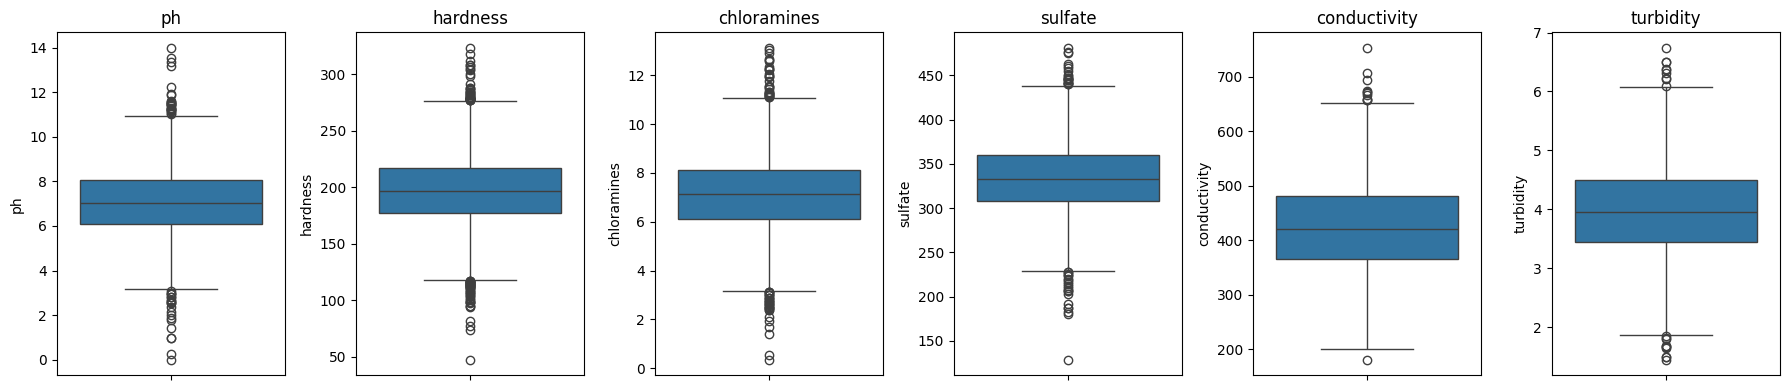

In [30]:
outlier_report = {}
for col in FEATURES:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier_report[col] = int(((df[col] < lo) | (df[col] > hi)).sum())
display(pd.Series(outlier_report, name="IQR outliers").to_frame())

fig, axes = plt.subplots(1, len(FEATURES), figsize=(3 * len(FEATURES), 4))
for ax, col in zip(np.atleast_1d(axes), FEATURES):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [31]:
counts = df[TARGET].value_counts().sort_index()
display(pd.DataFrame({"count": counts, "share": (counts / counts.sum()).round(3)},
                     index=pd.Index([0, 1], name="potability (0=not, 1=potable)")))

,count,share
"potability (0=not, 1=potable)",,
0,1998,0.61
1,1278,0.39


use F1 or ROC-AUC as evaluation metric rather than accuracy and use a stratified split.

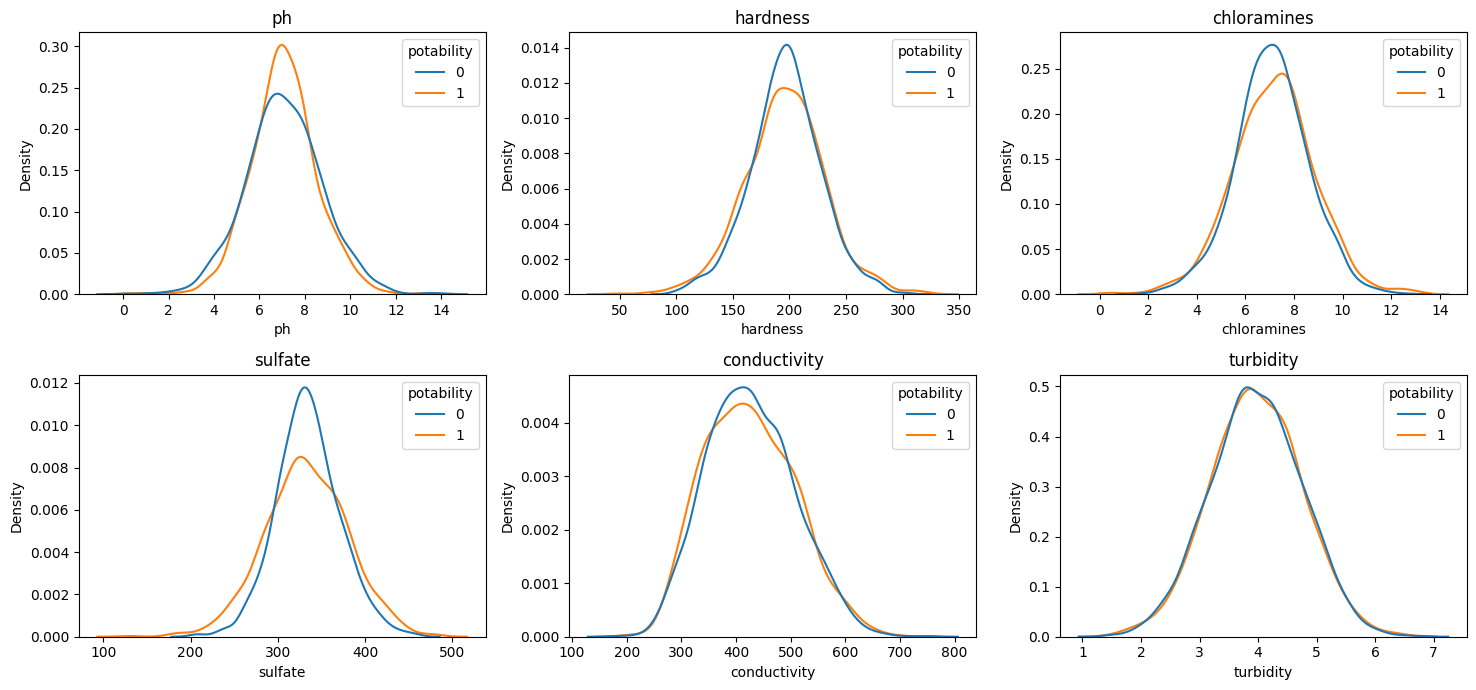

In [32]:
n = len(FEATURES)
ncols = 3
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.5 * nrows))
axes = np.atleast_1d(axes).ravel()
for ax, col in zip(axes, FEATURES):
    sns.kdeplot(data=df, x=col, hue=TARGET, common_norm=False, ax=ax)
    ax.set_title(col)
for ax in axes[n:]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

Distributions by class
overlapping curves so the features barely separate the classes. Probably a pretty poor accuracy...

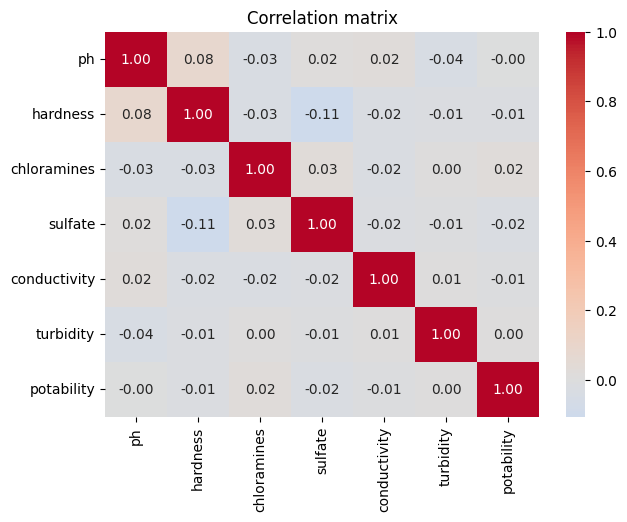

In [33]:
plt.figure(figsize=(7, 5))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.show()

In [35]:
assert df[TARGET].notna().all(), "Target has missing values"
assert not df.duplicated().any(), "Duplicates remain"
assert df.columns.tolist() == FEATURES + [TARGET]
if "ph" in df.columns:
    assert df["ph"].dropna().between(0, 14).all()

print("Final shape:", df.shape)
display(df.head())

Final shape: (3276, 7)


,ph,hardness,chloramines,sulfate,conductivity,turbidity,potability
0,NaN,204.890455,7.300212,368.516441,564.308654,2.963135,0
1,3.716080,129.422921,6.635246,NaN,592.885359,4.500656,0
2,8.099124,224.236259,9.275884,NaN,418.606213,3.055934,0
3,8.316766,214.373394,8.059332,356.886136,363.266516,4.628771,0
4,9.092223,181.101509,6.546600,310.135738,398.410813,4.075075,0



- `water_potability_clean.csv` is the file you upload to GCS/S3.
- `feature_metadata.json` records each feature's range and median. Your Streamlit app can use it for slider bounds and defaults, and your README can cite it.

In [36]:
df.to_csv(OUTPUT_CSV, index=False)

metadata = {
    "source": "https://www.kaggle.com/datasets/uom190346a/water-quality-and-potability",
    "target": TARGET,
    "dropped_columns": cols_to_drop,
    "n_rows": int(len(df)),
    "class_balance": {str(k): int(v) for k, v in df[TARGET].value_counts().items()},
    "features": {
        col: {
            "min": round(float(df[col].min()), 3),
            "max": round(float(df[col].max()), 3),
            "median": round(float(df[col].median()), 3),
            "pct_missing": round(float(df[col].isna().mean() * 100), 1),
        }
        for col in FEATURES
    },
}
with open(OUTPUT_META, "w") as f:
    json.dump(metadata, f, indent=2)

print(json.dumps(metadata, indent=2))

{
  "source": "https://www.kaggle.com/datasets/uom190346a/water-quality-and-potability",
  "target": "potability",
  "dropped_columns": [
    "Organic_carbon",
    "Trihalomethanes",
    "Solids"
  ],
  "n_rows": 3276,
  "class_balance": {
    "0": 1998,
    "1": 1278
  },
  "features": {
    "ph": {
      "min": 0.0,
      "max": 14.0,
      "median": 7.037,
      "pct_missing": 15.0
    },
    "hardness": {
      "min": 47.432,
      "max": 323.124,
      "median": 196.968,
      "pct_missing": 0.0
    },
    "chloramines": {
      "min": 0.352,
      "max": 13.127,
      "median": 7.13,
      "pct_missing": 0.0
    },
    "sulfate": {
      "min": 129.0,
      "max": 481.031,
      "median": 333.074,
      "pct_missing": 23.8
    },
    "conductivity": {
      "min": 181.484,
      "max": 753.343,
      "median": 421.885,
      "pct_missing": 0.0
    },
    "turbidity": {
      "min": 1.45,
      "max": 6.739,
      "median": 3.955,
      "pct_missing": 0.0
    }
  }
}


In [37]:
from google.colab import files
files.download(OUTPUT_CSV)
files.download(OUTPUT_META)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>